In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Dataset Selection and Reading

In [8]:
file_name = "DOC-20261107-WA0014.csv"
df = pd.read_csv('IMDB Dataset.csv')

print("--- Dataset Head ---")
print(df.head())

print("\n--- Dataset Info ---")
print(df.info())

print("\n--- Dataset Summary Statistics ---")
print(df.describe(include='all'))

--- Dataset Head ---
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
None

--- Dataset Summary Statistics ---
                                                   review sentiment
count                                               50000     50000
unique                                              49582         2
top     Loved today's show!!! It was a variety 

Data Transformation

In [9]:
df['review_length'] = df['review'].astype(str).apply(len)
df['sentiment'] = df['sentiment'].astype('category')
np.random.seed(42)
df['user_rating'] = np.random.choice([1, 2, 3, 4, 5, np.nan], size=len(df), p=[0.1, 0.1, 0.2, 0.3, 0.2, 0.1])
print("Null values before handling:\n", df.isnull().sum())

Null values before handling:
 review              0
sentiment           0
review_length       0
user_rating      4977
dtype: int64


Handling Null Values

In [ ]:

mean_rating = df['user_rating'].mean()
df['user_rating'] = df['user_rating'].fillna(mean_rating)


print("\nNull values after mean imputation:\n", df.isnull().sum())


Null values after mean imputation:
 review           0
sentiment        0
review_length    0
user_rating      0
dtype: int64


 Insight Generation

In [11]:

sentiment_counts = df['sentiment'].value_counts()
print("Insight 1 - Sentiment Distribution:\n", sentiment_counts)

avg_length = df.groupby('sentiment', observed=False)['review_length'].mean()
print("\nInsight 2 - Average Review Length by Sentiment:\n", avg_length)

Insight 1 - Sentiment Distribution:
 sentiment
negative    25000
positive    25000
Name: count, dtype: int64

Insight 2 - Average Review Length by Sentiment:
 sentiment
negative    1294.06436
positive    1324.79768
Name: review_length, dtype: float64


Data Visualization

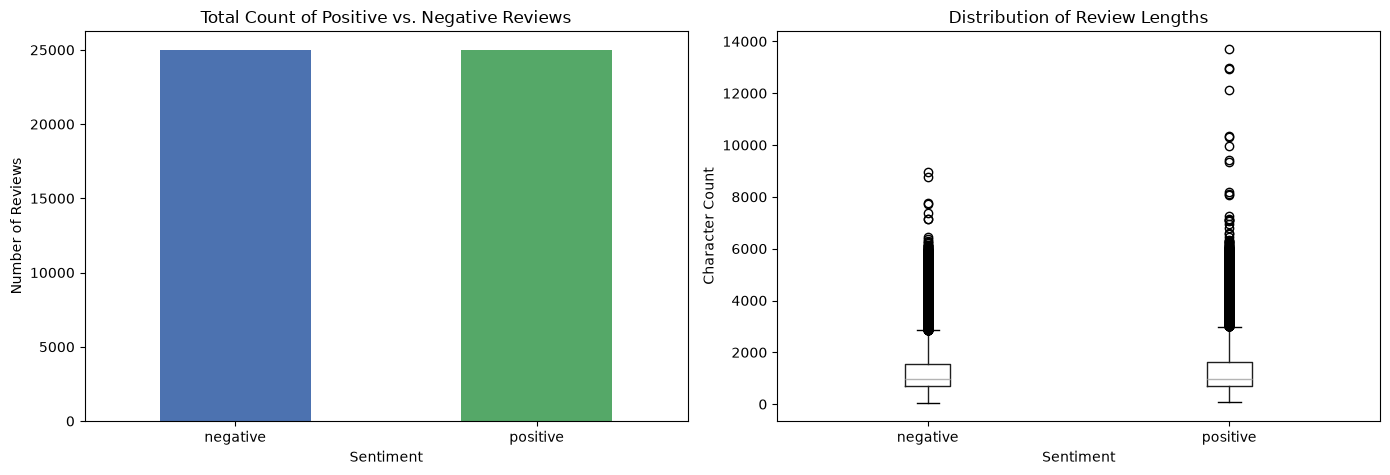

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sentiment_counts.plot(kind='bar', ax=axes[0], color=['#4C72B0', '#55A868'])
axes[0].set_title('Total Count of Positive vs. Negative Reviews')
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Number of Reviews')
axes[0].tick_params(axis='x', rotation=0)

df.boxplot(column='review_length', by='sentiment', ax=axes[1], grid=False)
axes[1].set_title('Distribution of Review Lengths')
axes[1].set_xlabel('Sentiment')
axes[1].set_ylabel('Character Count')

plt.suptitle('')
plt.tight_layout()
plt.show()